# NB 4/6 · Reinforcement Learning

Q-Learning · SARSA · TD(0) · TD(λ) · R-Learning · DQN

---
### References
[W]  Watkins C. & Dayan P. (1992) Q-Learning. *Mach. Learn.* **8**(3-4)  
[Ru] Rummery G. & Niranjan M. (1994) On-line Q-learning. *CUED Tech. Rep.*  
[S]  Sutton R.S. (1988) Learning to predict by TD methods. *Mach. Learn.* **3**(1)  
[Sc] Schwartz A. (1993) R-Learning. *Proc. ICML-93*  
[M]  Mnih V. et al. (2015) Human-level control via DRL. *Nature* **518**

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
import gymnasium as gym
from gymnasium import spaces
from stable_baselines3 import DQN
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.callbacks import BaseCallback
from shared_data import print_metrics
import warnings; warnings.filterwarnings('ignore')
np.random.seed(42); torch.manual_seed(42)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,
                     'axes.spines.right':False,'font.size':11})
STAGE_NAMES=['W','N1','N2','N3','REM']; N_STAGES=5; N_ACTIONS=3
ACTION_NAMES=['low_power','balanced','high_precision']
X_tr=np.load('X_tr.npy'); X_te=np.load('X_te.npy')
y_tr=np.load('y_tr.npy'); y_te=np.load('y_te.npy')
T=np.load('T.npy'); R_mdp=np.load('R_mdp.npy')
pol_vi=np.load('pol_vi.npy')
r_mdp_te=float(np.load('r_mdp_te.npy')[0])
print(f'PCA dim={X_tr.shape[1]}   MDP oracle reward={r_mdp_te:.1f}')

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


PCA dim=30   MDP oracle reward=8415.4


## §1 — Q-Learning (off-policy) [W]

Updates Q using the greedy next action, regardless of the behaviour policy:
$$Q(s,a)\leftarrow Q(s,a)+\alpha\Bigl[r+\gamma\max_{a'}Q(s',a')-Q(s,a)\Bigr]$$
Converges to $Q^*$ w.p.1 under decreasing step-sizes [W].

## §2 — SARSA (on-policy) [Ru]

Updates Q using the action *actually taken* in $s'$:
$$Q(s,a)\leftarrow Q(s,a)+\alpha\bigl[r+\gamma Q(s',a')-Q(s,a)\bigr]$$

## §3 — TD(0) — policy evaluation [S]

Estimates the state-value function for a fixed policy $\pi$:
$$V^\pi(s)\leftarrow V^\pi(s)+\alpha\bigl[r+\gamma V^\pi(s')-V^\pi(s)\bigr]$$

## §4 — TD(λ) — eligibility traces [S]

Bridges between TD(0) and Monte-Carlo by accumulating credit:
$$e_t(s,a)\leftarrow\gamma\lambda\,e_{t-1}(s,a)+\mathbf{1}[(s,a)=(s_t,a_t)]$$
$$Q(s,a)\leftarrow Q(s,a)+\alpha\,\delta_t\,e_t(s,a), \quad\delta_t=r+\gamma Q(s',a')-Q(s,a)$$

## §5 — R-Learning (average reward) [Sc]

Optimal for infinite-horizon tasks with no episode boundary — the long-run average reward $\rho$ is learned simultaneously:
$$Q(s,a)\leftarrow Q(s,a)+\alpha\bigl[r-\rho+\max_{a'}Q(s',a')-Q(s,a)\bigr]$$
$$\rho\leftarrow\rho+\beta\,\delta_t \quad\text{if }a=\arg\max Q(s,\cdot)$$

## §6 — DQN [M]

Approximates $Q^*(\mathbf{z}_t,a;\theta)$ with a neural network on the 30-dim PCA observation, using experience replay and a target network for stable off-policy learning.

In [2]:
# Tabular environment — wraps the DTMC + reward matrix
class TabEnv:
    def __init__(self, T, R): self.T, self.R, self.s = T, R, 0
    def reset(self): self.s = np.random.randint(N_STAGES); return self.s
    def step(self, a):
        r  = float(self.R[self.s, a])
        ns = np.random.choice(N_STAGES, p=self.T[self.s])
        self.s = ns; return ns, r, False

def eps_greedy(Q, s, eps):
    return np.random.randint(N_ACTIONS) if np.random.rand()<eps else int(Q[s].argmax())

def train_tabular(alg, n_ep=600, alpha=0.1, gamma=0.95, lam=0.7):
    Q   = np.zeros((N_STAGES, N_ACTIONS)); eps = 1.0; rews = []
    env = TabEnv(T, R_mdp)
    for ep in range(n_ep):
        eps = max(0.05, eps*0.992); s = env.reset(); tot = 0.
        if alg == 'tdl': e = np.zeros_like(Q)
        for _ in range(300):
            a = eps_greedy(Q, s, eps); ns, r, _ = env.step(a); tot += r
            if   alg == 'q':
                Q[s,a] += alpha*(r + gamma*Q[ns].max() - Q[s,a])
            elif alg == 'sarsa':
                na = eps_greedy(Q, ns, eps)
                Q[s,a] += alpha*(r + gamma*Q[ns,na] - Q[s,a])
            elif alg == 'tdl':
                na = eps_greedy(Q, ns, eps)
                d  = r + gamma*Q[ns,na] - Q[s,a]
                e[s,a] += 1.; Q += alpha*d*e; e *= gamma*lam
            s = ns
        rews.append(tot)
    return Q, rews

print('Training Q-Learning ...');  Q_ql,  r_ql  = train_tabular('q')
print('Training SARSA ...');       Q_sa,  r_sa  = train_tabular('sarsa')
print('Training TD(lambda) ...');  Q_tdl, r_tdl = train_tabular('tdl')
print('Done.')

Training Q-Learning ...
Training SARSA ...
Training TD(lambda) ...
Done.


In [3]:
# TD(0) policy evaluation under Q-Learning policy
pol_ql = Q_ql.argmax(1)
V_td0  = np.zeros(N_STAGES); alpha = 0.1
for t in range(len(y_tr)-1):
    s, ns = int(y_tr[t]), int(y_tr[t+1])
    V_td0[s] += alpha*(R_mdp[s,pol_ql[s]] + 0.95*V_td0[ns] - V_td0[s])
V_vi = np.load('V_vi.npy')
print('TD(0) vs V* (Value Iteration):')
for s in range(N_STAGES):
    print(f'  {STAGE_NAMES[s]:>4}: TD(0)={V_td0[s]:.4f}  V*={V_vi[s]:.4f}')

TD(0) vs V* (Value Iteration):
     W: TD(0)=17.6931  V*=18.3935
    N1: TD(0)=17.6096  V*=17.9740
    N2: TD(0)=17.6946  V*=18.0909
    N3: TD(0)=17.6096  V*=17.6974
   REM: TD(0)=17.6536  V*=17.8032


In [4]:
# R-Learning
Q_r  = np.zeros((N_STAGES, N_ACTIONS)); rho = 0.; beta = 0.01; eps = 1.
r_rl_ep = []; env_r = TabEnv(T, R_mdp)
for ep in range(600):
    eps = max(0.05, eps*0.992); s = env_r.reset(); tot = 0.
    for _ in range(300):
        a = eps_greedy(Q_r, s, eps); ns, r, _ = env_r.step(a)
        d = r - rho + Q_r[ns].max() - Q_r[s,a]
        Q_r[s,a] += 0.1*d
        if Q_r[s].argmax() == a: rho += beta*d
        tot += r; s = ns
    r_rl_ep.append(tot)
print(f'R-Learning: rho (avg reward) = {rho:.4f}')
for s in range(N_STAGES):
    print(f'  {STAGE_NAMES[s]:>4} -> {ACTION_NAMES[Q_r[s].argmax()]}')

R-Learning: rho (avg reward) = 0.9173
     W -> low_power
    N1 -> high_precision
    N2 -> low_power
    N3 -> high_precision
   REM -> high_precision


In [5]:
# DQN — 30-dim PCA random vector as Gym observation
class SleepGym(gym.Env):
    metadata = {'render_modes': []}
    def __init__(self, X, y):
        super().__init__()
        self.X, self.y, self.idx = X.astype(np.float32), y, 0
        self.observation_space = spaces.Box(-np.inf, np.inf, (X.shape[1],), np.float32)
        self.action_space = spaces.Discrete(N_ACTIONS)
    def reset(self, seed=None, options=None):
        super().reset(seed=seed); self.idx = 0; return self.X[0], {}
    def step(self, a):
        s   = int(self.y[self.idx]); r = float(R_mdp[s, int(a)])
        self.idx += 1; done = self.idx >= len(self.X)
        obs = np.zeros_like(self.X[0]) if done else self.X[self.idx]
        return obs, r, done, False, {}

class RewLog(BaseCallback):
    def __init__(self): super().__init__(); self.ep_rews = []; self._c = 0.
    def _on_step(self):
        self._c += float(self.locals.get('rewards',[0])[0])
        if self.locals.get('dones',[False])[0]:
            self.ep_rews.append(self._c); self._c = 0.
        return True

env_gym = SleepGym(X_tr, y_tr); check_env(env_gym, warn=True)
cb = RewLog()
dqn_m = DQN('MlpPolicy', env_gym, verbose=0,
            learning_rate=1e-3, buffer_size=30000,
            learning_starts=1000, batch_size=64, gamma=0.95,
            exploration_fraction=0.20, exploration_final_eps=0.05, seed=42)
print('Training DQN (20 000 steps) ...')
dqn_m.learn(20000, callback=cb); print('Done.')
te_env = SleepGym(X_te, y_te); obs, _ = te_env.reset(); done = False; dqn_rew = 0.
while not done:
    act, _ = dqn_m.predict(obs, deterministic=True)
    obs, r, term, trunc, _ = te_env.step(int(act))
    dqn_rew += r; done = term or trunc
print(f'DQN test reward: {dqn_rew:.1f}   MDP oracle: {r_mdp_te:.1f}')

Training DQN (20 000 steps) ...
Done.
DQN test reward: 7782.7   MDP oracle: 8415.4


Test-set reward comparison:
 Algorithm Test reward vs Oracle % of Oracle
MDP oracle      8415.4      +0.0       100.0
Q-Learning      8415.4      +0.0       100.0
     SARSA      8415.4      +0.0       100.0
TD(lambda)      8415.4      +0.0       100.0
R-Learning      8415.4      +0.0       100.0
       DQN      7782.7    +632.7        92.5


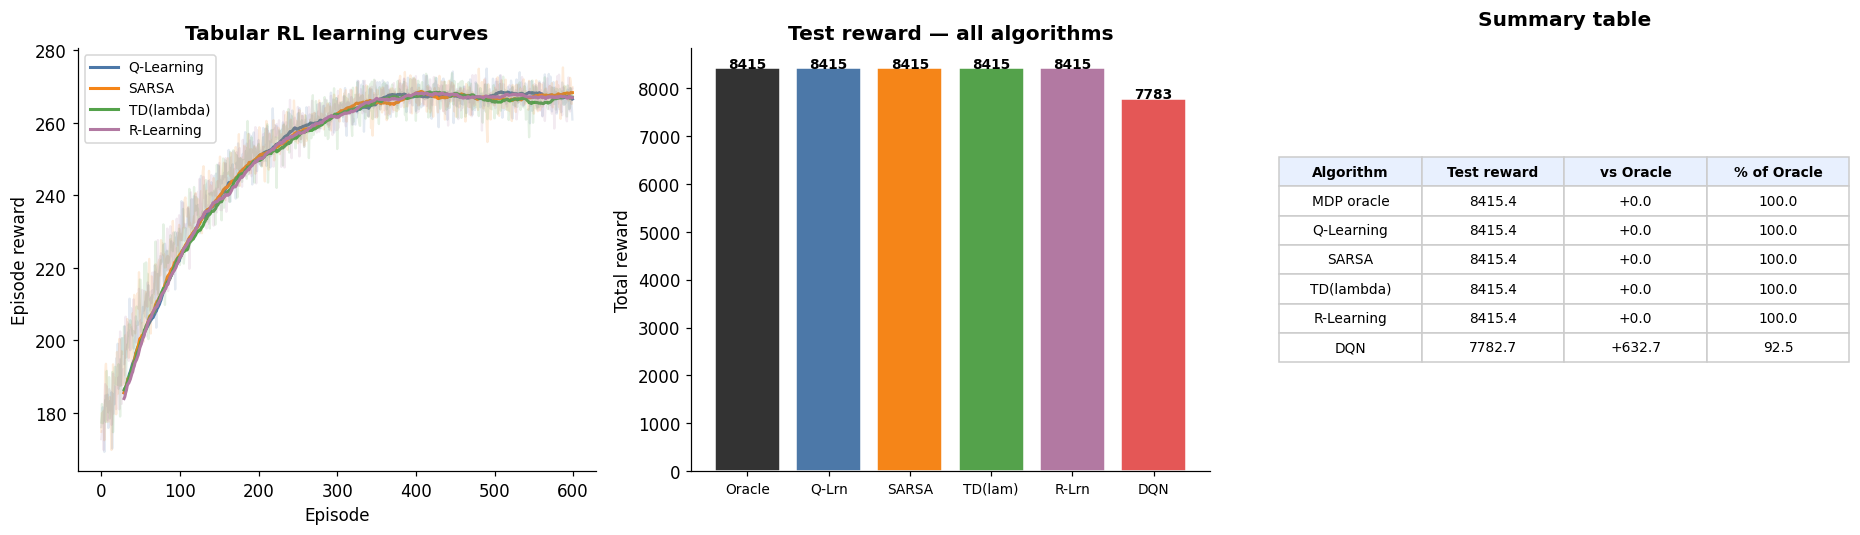

RL artefacts saved.


In [6]:
# ── reward helper (defined here to avoid scope issues) ──
def total_reward(Q, y): return sum(R_mdp[int(s), Q[int(s)].argmax()] for s in y)

methods = ['MDP oracle','Q-Learning','SARSA','TD(lambda)','R-Learning','DQN']
rewards = [r_mdp_te,
           total_reward(Q_ql,  y_te),
           total_reward(Q_sa,  y_te),
           total_reward(Q_tdl, y_te),
           total_reward(Q_r,   y_te),
           dqn_rew]
cols_bar = ['#333333','#4c78a8','#f58518','#54a24b','#b279a2','#e45756']

summary = pd.DataFrame({
    'Algorithm':       methods,
    'Test reward':     [f'{r:.1f}' for r in rewards],
    'vs Oracle':       [f'{r_mdp_te-r:+.1f}' for r in rewards],
    '% of Oracle':     [f'{r/r_mdp_te*100:.1f}' for r in rewards],
})
print('Test-set reward comparison:')
print(summary.to_string(index=False))

# ── figure: learning curves (left) + bar + table (right) ──
fig = plt.figure(figsize=(17, 5))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax3 = fig.add_subplot(1, 3, 3)

# learning curves
sm = lambda x, w: np.convolve(x, np.ones(w)/w, 'valid')
w = 30
for rews, nm, col in [(r_ql,'Q-Learning','#4c78a8'),
                       (r_sa,'SARSA','#f58518'),
                       (r_tdl,'TD(lambda)','#54a24b'),
                       (r_rl_ep,'R-Learning','#b279a2')]:
    ax1.plot(rews, alpha=0.15, color=col)
    ax1.plot(range(w-1,len(rews)), sm(rews,w), lw=2, label=nm, color=col)
ax1.set_title('Tabular RL learning curves', fontweight='bold')
ax1.set_xlabel('Episode'); ax1.set_ylabel('Episode reward')
ax1.legend(fontsize=9)

# bar chart
bars = ax2.bar(range(len(methods)), rewards, color=cols_bar, edgecolor='white')
for b, v in zip(bars, rewards):
    ax2.text(b.get_x()+b.get_width()/2, v+5, f'{v:.0f}',
             ha='center', fontsize=9, fontweight='bold')
ax2.set_xticks(range(len(methods)))
ax2.set_xticklabels(['Oracle','Q-Lrn','SARSA','TD(lam)','R-Lrn','DQN'],
                     fontsize=9)
ax2.set_title('Test reward — all algorithms', fontweight='bold')
ax2.set_ylabel('Total reward')

# summary table rendered as figure (works in all Jupyter versions)
ax3.axis('off')
tbl_data = [summary.columns.tolist()] + summary.values.tolist()
tbl = ax3.table(cellText=summary.values.tolist(),
                colLabels=summary.columns.tolist(),
                loc='center', cellLoc='center')
tbl.auto_set_font_size(False); tbl.set_fontsize(9)
tbl.scale(1.1, 1.6)
for (r,_), cell in tbl.get_celld().items():
    cell.set_edgecolor('#cccccc')
    if r == 0: cell.set_facecolor('#e8f0fe'); cell.set_text_props(fontweight='bold')
    else:      cell.set_facecolor('#ffffff')
ax3.set_title('Summary table', fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig('fig7_rl.png', bbox_inches='tight'); plt.show()

np.save('Q_ql.npy', Q_ql); np.save('dqn_rew.npy', np.array([dqn_rew]))
print('RL artefacts saved.')